# Machine Learning in Finance: a 1-hour lesson

**All data in this notebook is simulated**, so it runs offline and we know the "true" answer, which makes the ideas easier to see.

## Lesson plan (60 min)

| Min | Part | Slides covered |
|---|---|---|
| 0-7 | 1. What is ML? Finance applications, $Y=f(X)+\epsilon$ | Basics of ML |
| 7-17 | 2. Linear models: beta of a stock, OLS, $R^2$ | Linear models |
| 17-27 | 3. Loss, train vs test error, bias-variance trade-off | Basics of ML |
| 27-37 | 4. Resampling: validation set, LOOCV, K-fold, bootstrap | Resampling |
| 37-45 | 5. Decision trees: loan default, pruning | Trees |
| 45-52 | 6. Bagging and random forests, OOB, importance | Forests |
| 52-58 | 7. Neural networks | Neural networks |
| 58-60 | 8. Wrap-up quiz | |

Each part has a short *Discuss* or *Try it* prompt. Instructor notes are marked with 🎓.

In [17]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, KFold, LeaveOneOut, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, roc_auc_score
import yfinance as yf
import warnings; warnings.filterwarnings("ignore")

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(42)

df = yf.download("SPY", start="2020-01-01", end="2026-01-01", progress=False)
df.columns = df.columns.droplevel(1)

## 1. What is machine learning? (7 min)

**Big data from a statistical view:** $n$ = number of observations, $p$ = number of features. *Big n* needs efficient algorithms; *big p* needs structural assumptions.

**Machine learning** extracts patterns from data with an emphasis on **prediction accuracy**. Data are assumed to come from a random process, so conclusions are probabilistic. Better predictions come from *more / better data* or *better algorithms*.

**Statistical learning model:**
$$Y = f(X) + \epsilon, \qquad \hat Y = \hat f(X)$$
where $f$ is unknown and $\epsilon$ is mean-zero noise. Total error = *reducible* error (our $\hat f$ is imperfect) + *irreducible* error ($\epsilon$).

| | Supervised | Unsupervised |
|---|---|---|
| Data | $(X, Y)$ | only $X$ |
| Tasks | Regression ($Y$ numeric), Classification ($Y$ categorical) | Clustering, e.g. market segmentation |

**Finance examples:** fraud detection in loan applications, automated underwriting / credit scoring, stock price prediction, real estate price prediction.

> 💬 **Discuss (2 min):** For each of these, is it regression or classification? (a) Will this borrower default? (b) What will this house sell for? (c) Group customers by behaviour.

<details><summary>Explanation</summary>(a) classification: default or no default is a category. (b) regression: a price is a continuous number. (c) unsupervised clustering: there is no label Y, only the features X.</details>

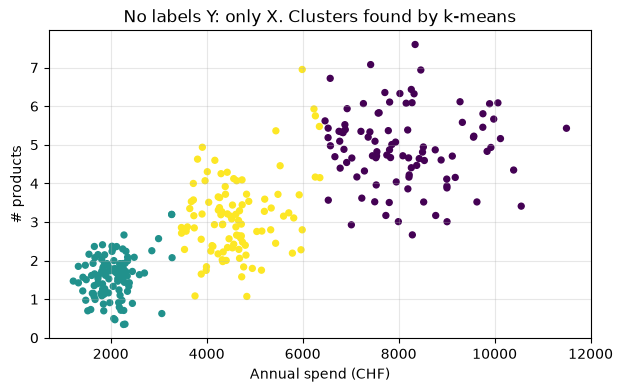

In [18]:
# Unsupervised learning in 10 lines: customer segmentation with k-means
from sklearn.cluster import KMeans
cust = pd.DataFrame({
    "annual_spend": np.r_[rng.normal(2000, 400, 100), rng.normal(8000, 1200, 100), rng.normal(4500, 700, 100)],
    "n_products": np.r_[rng.normal(1.5, .5, 100), rng.normal(5, 1, 100), rng.normal(3, .8, 100)],
})
cust["segment"] = KMeans(3, n_init=10, random_state=0).fit_predict(cust)
plt.scatter(cust.annual_spend, cust.n_products, c=cust.segment, cmap="viridis", s=18)
plt.xlabel("Annual spend (CHF)"); plt.ylabel("# products"); plt.title("No labels Y: only X. Clusters found by k-means"); plt.show()

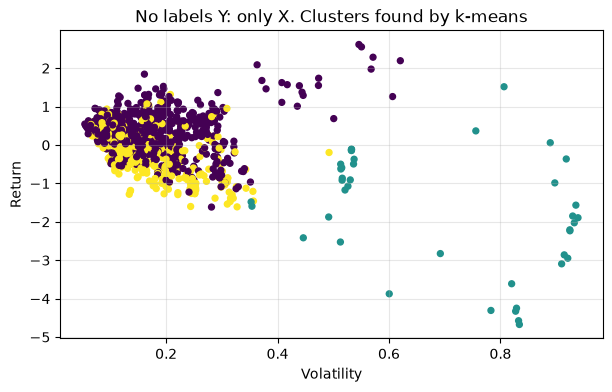

In [19]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Assuming `df` has daily 'Close' and 'Volume'
df["log_ret"] = np.log(df["Close"] / df["Close"].shift(1))

features = pd.DataFrame({
    "volatility_20d": df["log_ret"].rolling(20).std() * np.sqrt(252), # Annualized vol
    "return_20d":     df["log_ret"].rolling(20).mean() * 252,
    "vol_zscore":     (df["Volume"] - df["Volume"].rolling(20).mean()) / df["Volume"].rolling(20).std()
}).dropna()

# Scale features so Euclidean distance treats them equally
X_scaled = StandardScaler().fit_transform(features)

features["regime"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(X_scaled)
plt.scatter(features.volatility_20d, features.return_20d, c=features.regime, cmap="viridis", s=18)
plt.xlabel("Volatility"); plt.ylabel("Return"); plt.title("No labels Y: only X. Clusters found by k-means"); plt.show()

## 2. Linear models (10 min)

**Regression analysis = the study of dependence.** Finance classic: a stock's **beta** measures its sensitivity to a benchmark (e.g. the S&P 500).

Simple linear regression: $Y_i = \beta_0 + \beta_1 x_i + \epsilon_i$, with $E(\epsilon_i)=0$ and constant variance.

**OLS** minimises the residual sum of squares $\sum (y_i-\beta_0-\beta_1x_i)^2$, giving
$$\hat\beta_1 = \frac{S_{xy}}{S_{xx}} = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}, \qquad \hat\beta_0 = \bar y - \hat\beta_1 \bar x$$

**Variation decomposition:** Total SS = SS(reg) + RSS, so $R^2 = 1 - \text{RSS}/\text{Total SS}\in[0,1]$.

beta_hat = 1.734   alpha_hat = -0.00122   R^2 = 0.038
sklearn : beta = 1.734  alpha = -0.00122


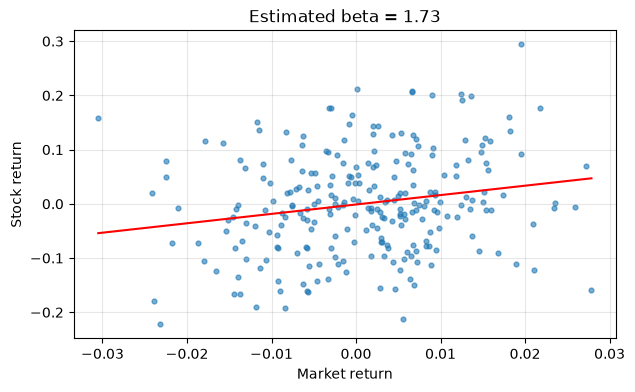

In [61]:
# Simulate daily returns: true alpha = 0.0002, true beta = 1.3
n = 250
mkt = rng.normal(0.0005, 0.01, n)
stock = 0.0002 + 1.3 * mkt + rng.normal(0, 0.1, n)

# OLS "by hand" using the formulas from the slides
Sxy = np.sum((mkt - mkt.mean()) * (stock - stock.mean()))
Sxx = np.sum((mkt - mkt.mean()) ** 2)
b1 = Sxy / Sxx
b0 = stock.mean() - b1 * mkt.mean()

fit = b0 + b1 * mkt
RSS = np.sum((stock - fit) ** 2)
TSS = np.sum((stock - stock.mean()) ** 2)
print(f"beta_hat = {b1:.3f}   alpha_hat = {b0:.5f}   R^2 = {1 - RSS/TSS:.3f}")

# Check against scikit-learn
lr = LinearRegression().fit(mkt.reshape(-1, 1), stock)
print(f"sklearn : beta = {lr.coef_[0]:.3f}  alpha = {lr.intercept_:.5f}")

plt.scatter(mkt, stock, s=12, alpha=.6); xs = np.linspace(mkt.min(), mkt.max(), 2)
plt.plot(xs, b0 + b1 * xs, "r"); plt.xlabel("Market return"); plt.ylabel("Stock return")
plt.title(f"Estimated beta = {b1:.2f}"); plt.show()

**Interpretation.** $\hat\beta_1$ is the expected change in the stock return for a one-unit change in the market return. A beta above 1 means the stock amplifies market moves. $R^2$ tells us the share of the stock's variance explained by the market; the rest is idiosyncratic risk.

**Multiple linear regression** just adds more covariates: $y_i=\beta_0+\beta_1x_{i1}+\dots+\beta_kx_{ik}+\epsilon_i$.

> 🧪 **Try it (2 min):** Change the noise level `0.008` to `0.02`. What happens to $R^2$ and to the *accuracy* of $\hat\beta_1$?

## 3. Measuring success: loss, risk, train vs test, bias-variance (10 min)

- **Loss function** $L(Y,\hat f(X))$: squared error for regression, **0-1 loss** for classification.
- **Risk** $R(f)=E[L(Y,f(X))]$ cannot be computed (unknown distribution), so we estimate it with the **empirical risk** (training error).
- But what we care about is the **test error** on *new* data.

More flexible models always lower the *training* error, but the *test* error is U-shaped:
$$E(Y_0-\hat f(x_0))^2 = \text{Var}(\hat f(x_0)) + \text{Bias}(\hat f(x_0))^2 + \text{Var}(\epsilon)$$

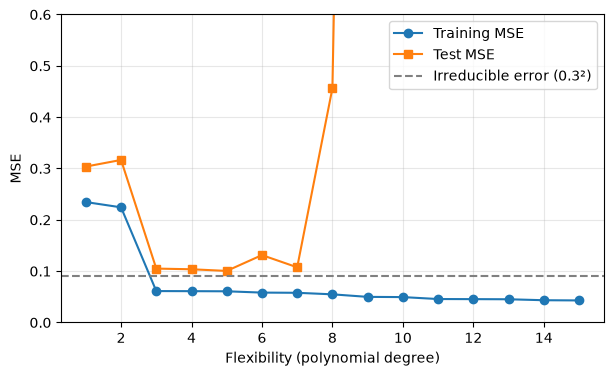

Best degree on test data: 5


In [50]:
# True relationship (unknown to the learner): f(x) = sin(x); noise sd = 0.3
f = np.sin
def make(n):
    x = rng.uniform(-3, 3, n); return x.reshape(-1, 1), f(x) + rng.normal(0, 0.3, n)

Xtr, ytr = make(40); Xte, yte = make(2000)
degrees = range(1, 16)
tr_mse, te_mse = [], []
for d in degrees:
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(Xtr, ytr)
    tr_mse.append(np.mean((ytr - m.predict(Xtr))**2)); te_mse.append(np.mean((yte - m.predict(Xte))**2))

plt.plot(degrees, tr_mse, "o-", label="Training MSE"); plt.plot(degrees, te_mse, "s-", label="Test MSE")
plt.axhline(0.09, ls="--", c="gray", label="Irreducible error (0.3²)")
plt.ylim(0, 0.6); plt.xlabel("Flexibility (polynomial degree)"); plt.ylabel("MSE"); plt.legend(); plt.show()
print("Best degree on test data:", list(degrees)[int(np.argmin(te_mse))])

🎓 Ask: *why does training MSE keep falling while test MSE rises again?*

**Take-away:** simple models = high bias, low variance; flexible models = low bias, high variance. *More complex is not always better.*

**Flexibility vs interpretability:** linear < trees < forests / neural nets in flexibility; usually the reverse for interpretability.

## 4. Resampling approaches (10 min)

We rarely have a huge separate test set, so we **repeatedly resample the training data** to (i) assess models, (ii) select flexibility, (iii) reduce variance (bagging).

We replicate the slides' *Auto* example (predict `mpg` from `horsepower`; here simulated, 392 observations) and compare `mpg ~ hp` vs `mpg ~ hp + hp²`.

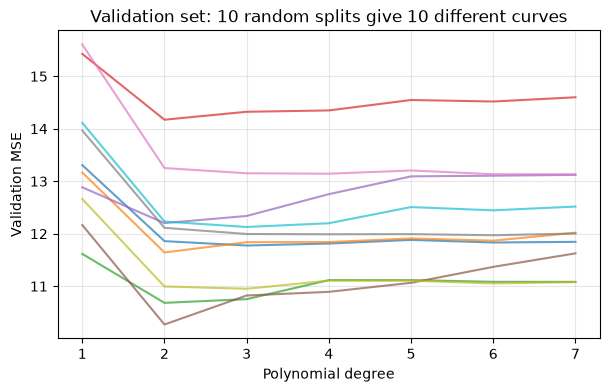

In [23]:
n = 392
hp = rng.uniform(46, 230, n)
mpg = 40 - 0.25*hp + 0.0006*hp**2 + rng.normal(0, 3.5, n)
auto = pd.DataFrame({"hp": hp, "mpg": mpg})
X, y = auto[["hp"]].values, auto["mpg"].values
def model(d): return make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())

# 4a. Validation-set approach, repeated with 10 different random splits
plt.figure()
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.5, random_state=s)
    errs = [np.mean((yb - model(d).fit(Xa, ya).predict(Xb))**2) for d in range(1, 8)]
    plt.plot(range(1, 8), errs, alpha=.7)
plt.xlabel("Polynomial degree"); plt.ylabel("Validation MSE"); plt.title("Validation set: 10 random splits give 10 different curves"); plt.show()

**Validation set:** simple, but the MSE is **highly variable**, and only half of the data is used for fitting, so it tends to **overestimate** the test error.

**LOOCV** trains on $n-1$ points and tests on 1, repeated $n$ times: $CV_n=\frac1n\sum_i (Y_i-\hat f^{(-i)}(X_i))^2$. Less bias and *no randomness* in the split, but it is computationally expensive.

**K-fold CV** ($K=5$ or $10$): $CV_K=\sum_k \frac{n_k}{n}MSE_k$. LOOCV is the special case $K=n$. K-fold has a bit more bias but lower variance, and is the usual compromise.

In [51]:
import time
res = []
for name, cv in [("10-fold CV", KFold(10, shuffle=True, random_state=1)), ("LOOCV", LeaveOneOut())]:
    t = time.time()
    mses = [-cross_val_score(model(d), X, y, cv=cv, scoring="neg_mean_squared_error").mean() for d in range(1, 6)]
    res.append((name, mses, time.time() - t))
    print(f"{name:10s} MSE by degree 1..5: {np.round(mses, 2)}   ({res[-1][2]:.1f}s)")
print("\nBoth methods agree: degree 1 is clearly worse, and degrees >= 2 are almost indistinguishable (true model is quadratic).")
print("LOOCV gives essentially the same curve but takes far longer.")

10-fold CV MSE by degree 1..5: [0.37 0.4  0.12 0.13 0.14]   (0.2s)
LOOCV      MSE by degree 1..5: [0.36 0.37 0.13 0.13 0.14]   (0.7s)

Both methods agree: degree 1 is clearly worse, and degrees >= 2 are almost indistinguishable (true model is quadratic).
LOOCV gives essentially the same curve but takes far longer.


### The bootstrap: quantifying uncertainty

Sample **with replacement** from the data $B$ times and recompute the statistic each time. The spread of the bootstrap estimates approximates the sampling variability.

Toy example from the slides: invest a fraction $\alpha$ in asset $X$ and $1-\alpha$ in $Y$ to minimise risk. The minimiser is
$$\alpha=\frac{\sigma_Y^2-\sigma_{XY}}{\sigma_X^2+\sigma_Y^2-2\sigma_{XY}}$$
With $\sigma_X^2=1,\ \sigma_Y^2=1.25,\ \sigma_{XY}=0.5$ the true $\alpha=0.6$.

Population simulation : mean = 0.600, SE = 0.084
Bootstrap (1 sample)  : mean = 0.594, SE = 0.059
90% bootstrap percentile CI: [0.499 0.69 ]


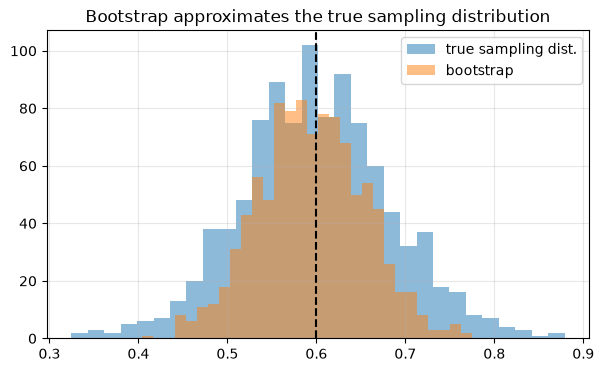

Share of distinct obs in a bootstrap sample: 0.623


In [62]:
cov = [[1, .5], [.5, 1.25]]
def alpha_hat(d):
    C = np.cov(d.T); return (C[1,1] - C[0,1]) / (C[0,0] + C[1,1] - 2*C[0,1])

# (i) If we could draw from the population: 1000 fresh samples of n=100
sim = np.array([alpha_hat(rng.multivariate_normal([0, 0], cov, 100)) for _ in range(1000)])
print(f"Population simulation : mean = {sim.mean():.3f}, SE = {sim.std(ddof=1):.3f}")

# (ii) In practice we have ONE sample: bootstrap it
data = rng.multivariate_normal([0, 0], cov, 100)
boot = np.array([alpha_hat(data[rng.integers(0, 100, 100)]) for _ in range(1000)])
print(f"Bootstrap (1 sample)  : mean = {boot.mean():.3f}, SE = {boot.std(ddof=1):.3f}")
print("90% bootstrap percentile CI:", np.percentile(boot, [5, 95]).round(3))

plt.hist(sim, 30, alpha=.5, label="true sampling dist."); plt.hist(boot, 30, alpha=.5, label="bootstrap")
plt.axvline(0.6, c="k", ls="--"); plt.legend(); plt.title("Bootstrap approximates the true sampling distribution"); plt.show()

# Why bootstrap samples contain ~63.2% of the original points: 1 - (1 - 1/n)^n -> 1 - e^-1
n_ = 1000; print("Share of distinct obs in a bootstrap sample:", len(np.unique(rng.integers(0, n_, n_))) / n_)

**CV vs bootstrap:** CV subsamples *without* replacement and estimates **test error**; the bootstrap samples *with* replacement and estimates the **variance of an estimator**. Using the bootstrap directly to estimate prediction error is biased downward because each bootstrap sample overlaps with the original data by ~63%.

> 💬 **Discuss:** Why does a random 50/50 split give a different answer each run, while LOOCV always gives the same one?

## 5. Decision trees (8 min)

A tree is a flowchart: *"Is quarterly earnings growth positive? Yes → ..."*. It partitions the predictor space into regions $R_1,\dots,R_J$ and predicts the **mean** (regression) or the **majority class** (classification) in each.

- Built **top-down and greedily** by *recursive binary splitting*, choosing the split that most reduces RSS (regression) or impurity (classification).
- Classification impurity measures: misclassification error $1-\hat p$, **Gini** $\sum \hat p(1-\hat p)$, **cross-entropy** $-\sum \hat p\log\hat p$.
- A big tree **overfits**, so use **cost-complexity pruning**: minimise $RSS(T)+\alpha|T|$, choosing $\alpha$ by cross-validation.

**Pros:** easy to explain, non-linear, handles mixed predictors. **Cons:** unstable (high variance), lower accuracy.

We use a simulated **loan default** dataset.

In [56]:
n = 4000
loans = pd.DataFrame({
    "income":        rng.lognormal(10.8, 0.4, n).round(-2),
    "debt_ratio":    rng.beta(2, 4, n),
    "age":           rng.integers(21, 70, n),
    "credit_years":  rng.integers(0, 30, n),
    "late_payments": rng.poisson(1.0, n),
    "noise_feature": rng.normal(size=n),          # irrelevant by construction
})
logit = (-2.6 + 3.0*loans.debt_ratio + 0.4*loans.late_payments - 0.00001*loans.income
         - 0.03*loans.credit_years + 2.0*((loans.debt_ratio > .5) & (loans.late_payments >= 2)))
loans["default"] = (rng.uniform(size=n) < 1/(1 + np.exp(-logit))).astype(int)
print("Default rate:", loans.default.mean().round(3)); display(loans.head())

Xl, yl = loans.drop(columns="default"), loans["default"]
Xtr, Xte, ytr, yte = train_test_split(Xl, yl, test_size=0.3, random_state=0, stratify=yl)

Default rate: 0.141


,income,debt_ratio,age,credit_years,late_payments,noise_feature,default
0,88300.0,0.472182,56,18,0,1.768694,0
1,61200.0,0.436082,42,3,1,1.004241,0
2,19700.0,0.141823,61,16,2,-0.823667,0
3,24200.0,0.334832,64,17,1,-0.252085,0
4,44400.0,0.367402,24,25,0,0.915915,0


Full tree  : 408 leaves | train acc 1.000 | test acc 0.798
Pruned tree: 3 leaves | train acc 0.881 | test acc 0.890  (alpha=0.00161)


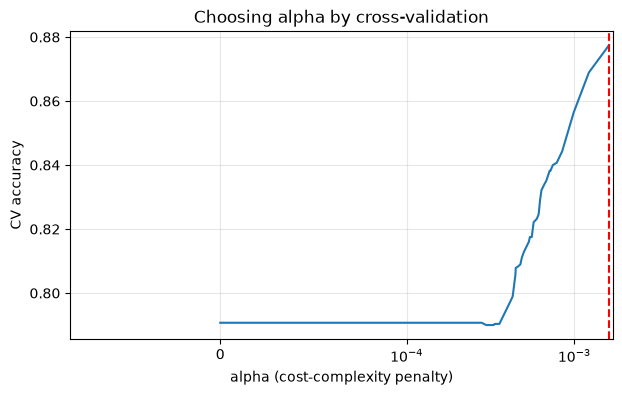

In [57]:
# Fully grown tree vs pruned tree
full = DecisionTreeClassifier(random_state=0).fit(Xtr, ytr)
print(f"Full tree  : {full.get_n_leaves()} leaves | train acc {full.score(Xtr, ytr):.3f} | test acc {full.score(Xte, yte):.3f}")

# Cost-complexity pruning: pick alpha by 5-fold CV
alphas = full.cost_complexity_pruning_path(Xtr, ytr).ccp_alphas[:-1]
alphas = alphas[::max(1, len(alphas)//40)]
cv_scores = [cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=0), Xtr, ytr, cv=5).mean() for a in alphas]
best_a = alphas[int(np.argmax(cv_scores))]
pruned = DecisionTreeClassifier(ccp_alpha=best_a, random_state=0).fit(Xtr, ytr)
print(f"Pruned tree: {pruned.get_n_leaves()} leaves | train acc {pruned.score(Xtr, ytr):.3f} | test acc {pruned.score(Xte, yte):.3f}  (alpha={best_a:.5f})")

plt.plot(alphas, cv_scores); plt.axvline(best_a, c="r", ls="--"); plt.xscale("symlog", linthresh=1e-4)
plt.xlabel("alpha (cost-complexity penalty)"); plt.ylabel("CV accuracy"); plt.title("Choosing alpha by cross-validation"); plt.show()

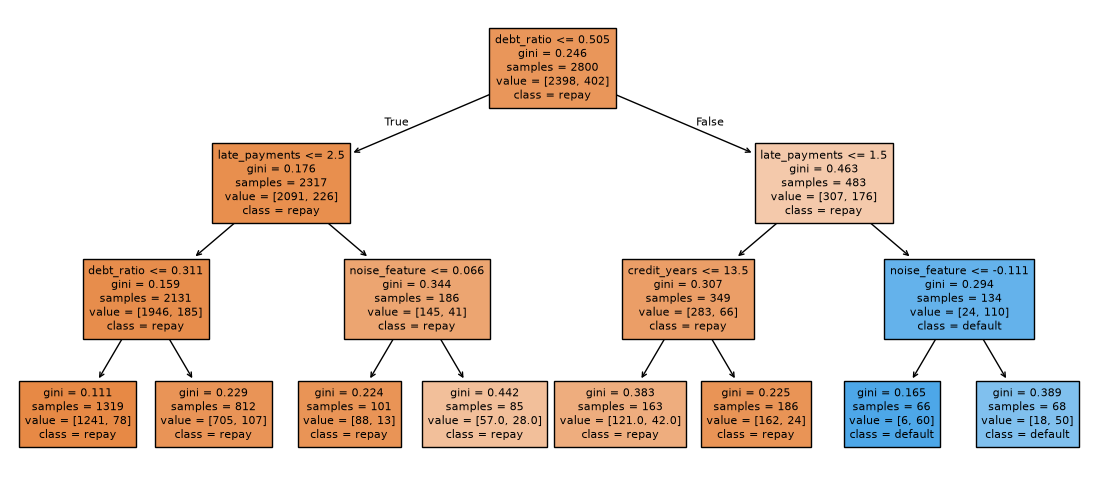

In [28]:
small = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=0).fit(Xtr, ytr)
plt.figure(figsize=(14, 6)); plot_tree(small, feature_names=Xl.columns, class_names=["repay", "default"], filled=True, impurity=True, fontsize=8); plt.show()

> 🧪 **Try it:** change `random_state` in `train_test_split` and refit the full tree. How much does its structure/accuracy change? (This instability is exactly why we move to forests.)

## 6. Bagging and random forests (7 min)

Trees have **high variance**. If we could draw many training sets and average the trees, variance would shrink: $\hat f_{avg}(x)=\frac1B\sum_b\hat f_b(x)$. We can't, so we **bootstrap**: *bagging* = bootstrap aggregation (average for regression, majority vote for classification).

**Random forest** (Breiman, 2001) = bagging + **random subset of `mtry` predictors at each split**, which de-correlates trees and reduces variance further. Bagging is the special case `mtry = p`.

Main hyperparameters: number of trees $B$, node size, `mtry` (common starts: $p/3$ for regression, $\sqrt p$ for classification; $B=500$).

**Out-of-bag (OOB):** each tree sees ~2/3 of observations; the other ~1/3 act as a free test set, so OOB error approximates test error without a validation set.

**Permutation importance:** shuffle one predictor in the OOB/test data and measure how much accuracy drops.

In [29]:
models = {
    "Single tree (pruned)": pruned,
    "Bagging (mtry = p)":   RandomForestClassifier(500, max_features=None, min_samples_leaf=5, oob_score=True, random_state=0, n_jobs=-1),
    "Random forest (sqrt p)": RandomForestClassifier(500, max_features="sqrt", min_samples_leaf=5, oob_score=True, random_state=0, n_jobs=-1),
}
rows = []
for name, m in models.items():
    if name != "Single tree (pruned)": m.fit(Xtr, ytr)
    rows.append({"model": name, "test accuracy": accuracy_score(yte, m.predict(Xte)),
                 "test AUC": roc_auc_score(yte, m.predict_proba(Xte)[:, 1]),
                 "OOB accuracy": getattr(m, "oob_score_", np.nan)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

                 model  test accuracy  test AUC  OOB accuracy
  Single tree (pruned)          0.888     0.708           NaN
    Bagging (mtry = p)          0.888     0.736         0.886
Random forest (sqrt p)          0.889     0.748         0.886


AUC represents the probability that the model assigns a higher predicted probability to a randomly chosen positive instance than to a randomly chosen negative instance:$$\text{AUC} = P\big(\hat{p}(\text{positive}) > \hat{p}(\text{negative})\big)$$

- AUC = 1.0: Perfect classifier (every positive case gets a higher score than every negative case).
- AUC = 0.5: No discriminative power—equivalent to random guessing (a coin flip).
- AUC < 0.5: Worse than random guessing (the model is systematically ranking negatives higher than positives).

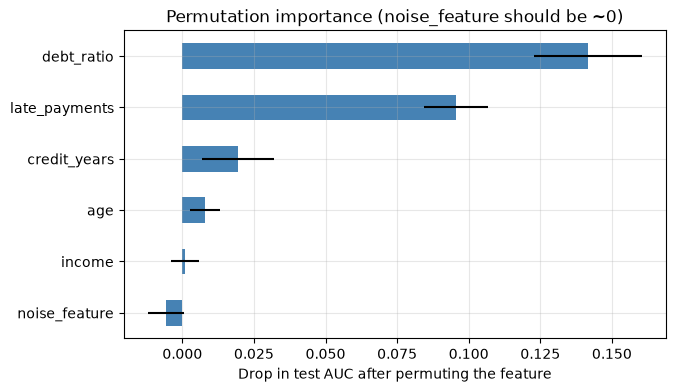

In [30]:
rf = models["Random forest (sqrt p)"]
pi = permutation_importance(rf, Xte, yte, n_repeats=20, random_state=0, scoring="roc_auc", n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=Xl.columns).sort_values()
imp.plot.barh(xerr=pd.Series(pi.importances_std, index=Xl.columns)[imp.index], color="steelblue")
plt.xlabel("Drop in test AUC after permuting the feature"); plt.title("Permutation importance (noise_feature should be ~0)"); plt.show()

**Summary:** single trees are interpretable but unstable; bagging and random forests cut variance and are state-of-the-art for tabular data, at the cost of interpretability (importance measures help).

## 7. Neural networks (6 min)

Inspired by the brain: **neurons** arranged in **layers** (input → hidden → output). More than one hidden layer = *deep*. Main families: **feedforward (FNN/MLP)**, **convolutional (CNN, images)**, **recurrent (RNN, sequences / time series)**.

Each hidden neuron computes a weighted sum of inputs and applies a **non-linear activation**, e.g. $h=f(\sum_j w_jx_j)$. Without non-linearity the whole network collapses to one linear model.

- **Sigmoid** $\frac1{1+e^{-z}}\in(0,1)$: output layer for binary classification; vanishing gradients in hidden layers.
- **Tanh** $\in(-1,1)$: zero-centred, same vanishing-gradient issue.
- **ReLU** $\max(0,z)$: the most popular hidden activation ("dying ReLU" risk).

**Training:** pick a loss (MSE, MAE, cross-entropy...), then iterate gradient descent: $w\leftarrow w-\alpha\,\partial L/\partial w$. The learning rate $\alpha$ trades speed against stability. Use training / validation / test sets to tune and detect over/underfitting.

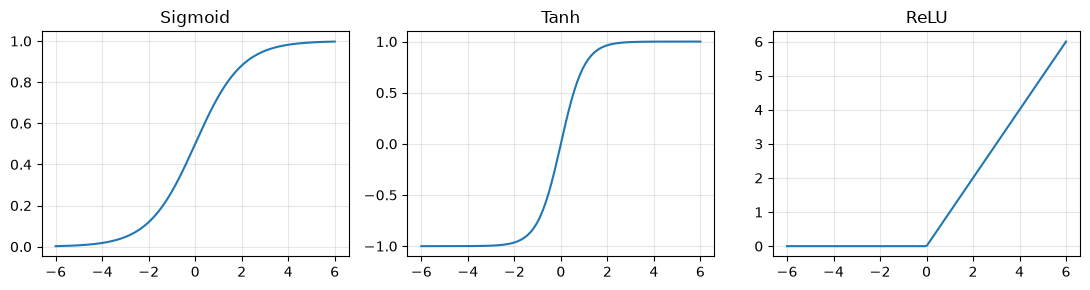

hidden activations: [0.983 1.749 0.589] | predicted default prob: [0.174]


In [31]:
z = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a, (n_, fn) in zip(ax, [("Sigmoid", 1/(1+np.exp(-z))), ("Tanh", np.tanh(z)), ("ReLU", np.maximum(0, z))]):
    a.plot(z, fn); a.set_title(n_)
plt.tight_layout(); plt.show()

# A tiny forward pass by hand: 2 inputs -> 3 hidden (ReLU) -> 1 output (sigmoid)
x = np.array([0.5, -1.0])
W1 = rng.normal(size=(2, 3)); W2 = rng.normal(size=(3, 1))
h = np.maximum(0, x @ W1); y_hat = 1/(1 + np.exp(-(h @ W2)))
print("hidden activations:", h.round(3), "| predicted default prob:", y_hat.round(3))

In [32]:
# Train an MLP on the loan data. Scaling the inputs matters for gradient-based training.
nn = make_pipeline(StandardScaler(), MLPClassifier((32, 16), activation="relu", alpha=1e-3, learning_rate_init=0.003,
                                                   early_stopping=True, max_iter=500, random_state=0)).fit(Xtr, ytr)
print(f"MLP    : test acc {nn.score(Xte, yte):.3f} | test AUC {roc_auc_score(yte, nn.predict_proba(Xte)[:,1]):.3f}")
print(f"Forest : test acc {rf.score(Xte, yte):.3f} | test AUC {roc_auc_score(yte, rf.predict_proba(Xte)[:,1]):.3f}")

MLP    : test acc 0.872 | test AUC 0.748
Forest : test acc 0.889 | test AUC 0.748


> 💬 **Discuss:** On small tabular data, forests often match or beat neural nets with less tuning. When would you expect neural networks to win? (Images, text, long time series, huge $n$.)